# Самостоятельная работа
1. Усложните модель(не используйте свёрточные слои, только nn.Linear).
2. Добавьте рассчёт train/val метрик.
3. Обучите модель на наборе данных CIFAR-10.
4. Возьмите более сложный датасет(желательно что бы он был как-то связан с транспортом).
5. Попробуйте обучить модель на нём
6. Посчитайте количество параметров вашей модели.
7. Визуализируйте loss и метрики
8. Проверьте финальное качество своей модели на test выборке.

In [3]:
import torch
import matplotlib.pyplot as plt

from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets
from torchvision.transforms import v2

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")

Using cpu device


## 1. Более сложная MLP

In [4]:
cifar_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

cifar_full_train = datasets.CIFAR10(
    root="data",
    train=True,
    download=True,
    transform=cifar_transform,
)

cifar_test = datasets.CIFAR10(
    root="data",
    train=False,
    download=True,
    transform=cifar_transform,
)

train_size = int(0.8 * len(cifar_full_train))
val_size = len(cifar_full_train) - train_size

cifar_train, cifar_val = random_split(
    cifar_full_train,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42),
)

print("Train:", len(cifar_train))
print("Val:", len(cifar_val))
print("Test:", len(cifar_test))

100.0%


Train: 40000
Val: 10000
Test: 10000


In [5]:
batch_size = 64

cifar_train_loader = DataLoader(
    cifar_train, batch_size=batch_size, shuffle=True
)

cifar_val_loader = DataLoader(
    cifar_val, batch_size=batch_size, shuffle=False
)

cifar_test_loader = DataLoader(
    cifar_test, batch_size=batch_size, shuffle=False
)

здесь сеть сделана глубже чем в лекции

было 784 - 512 - 128 - 10

стало 3072 - 1024 - 512 - 256 - 128 - 10

In [6]:
class CIFAR10MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.layers_stack = nn.Sequential(
            nn.Linear(3 * 32 * 32, 1024),
            nn.ReLU(),

            nn.Linear(1024, 512),
            nn.ReLU(),

            nn.Linear(512, 256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.layers_stack(x)
        return logits


cifar_model = CIFAR10MLP().to(device)
print(cifar_model)

CIFAR10MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers_stack): Sequential(
    (0): Linear(in_features=3072, out_features=1024, bias=True)
    (1): ReLU()
    (2): Linear(in_features=1024, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): ReLU()
    (6): Linear(in_features=256, out_features=128, bias=True)
    (7): ReLU()
    (8): Linear(in_features=128, out_features=10, bias=True)
  )
)


### Кол-во параметров модели

In [7]:
def count_parameters(model):
    return sum(param.numel() for param in model.parameters() if param.requires_grad)


cifar_params = count_parameters(cifar_model)

print("Количество обучаемых параметров CIFAR-10 модели:", cifar_params)

Количество обучаемых параметров CIFAR-10 модели: 3837066


# 2. Расчет train/val метрик

In [8]:
def train_loop(dataloader, model, criterion, optimizer):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)

    train_loss = 0
    correct = 0

    model.train()

    for imgs, labels in dataloader:
        imgs = imgs.to(device)
        labels = labels.to(device)

        pred = model(imgs)
        loss = criterion(pred, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.detach().item()
        correct += (pred.argmax(dim=1) == labels).sum().item()

    train_loss /= num_batches
    train_accuracy = correct / size

    print(
        f"Train loss: {train_loss:>8f}, "
        f"train accuracy: {(100 * train_accuracy):>0.1f}%"
    )

    return train_loss, train_accuracy


def val_loop(dataloader, model, criterion):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)

    val_loss = 0
    correct = 0

    model.eval()

    with torch.no_grad():
        for imgs, labels in dataloader:
            imgs = imgs.to(device)
            labels = labels.to(device)

            pred = model(imgs)
            loss = criterion(pred, labels)

            val_loss += loss.item()
            correct += (pred.argmax(dim=1) == labels).sum().item()

    val_loss /= num_batches
    val_accuracy = correct / size

    print(
        f"Val loss: {val_loss:>8f}, "
        f"val accuracy: {(100 * val_accuracy):>0.1f}%\n"
    )

    return val_loss, val_accuracy

### Обучение CIFAR-10

In [9]:
num_epochs = 15
learning_rate = 1e-2

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    cifar_model.parameters(),
    lr=learning_rate
)

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
}

for epoch in range(num_epochs):
    print(f"Epoch {epoch + 1}")

    train_loss, train_accuracy = train_loop(
        cifar_train_loader,
        cifar_model,
        criterion,
        optimizer,
    )

    val_loss, val_accuracy = val_loop(
        cifar_val_loader,
        cifar_model,
        criterion,
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

print("Done")

Epoch 1
Train loss: 2.296694, train accuracy: 10.8%
Val loss: 2.286246, val accuracy: 17.2%

Epoch 2
Train loss: 2.236935, train accuracy: 19.3%
Val loss: 2.137700, val accuracy: 19.0%

Epoch 3
Train loss: 2.063058, train accuracy: 23.1%
Val loss: 2.013352, val accuracy: 25.8%

Epoch 4
Train loss: 1.969820, train accuracy: 27.1%
Val loss: 1.919985, val accuracy: 30.2%

Epoch 5
Train loss: 1.908477, train accuracy: 30.3%
Val loss: 1.868378, val accuracy: 32.1%

Epoch 6
Train loss: 1.863324, train accuracy: 32.3%
Val loss: 1.822525, val accuracy: 33.8%

Epoch 7
Train loss: 1.818780, train accuracy: 34.1%
Val loss: 1.785331, val accuracy: 35.8%

Epoch 8
Train loss: 1.772748, train accuracy: 35.9%
Val loss: 1.734679, val accuracy: 37.4%

Epoch 9
Train loss: 1.732667, train accuracy: 37.4%
Val loss: 1.726529, val accuracy: 37.8%

Epoch 10
Train loss: 1.699071, train accuracy: 38.8%
Val loss: 1.704490, val accuracy: 38.4%

Epoch 11
Train loss: 1.665542, train accuracy: 39.7%
Val loss: 1.6549

## Визуализация ф-и потерь

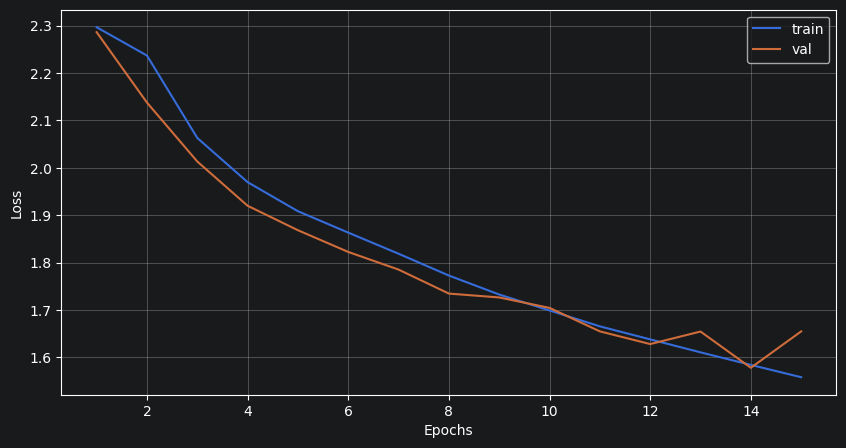

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, num_epochs + 1),
    history["train_loss"],
    label="train"
)

plt.plot(
    range(1, num_epochs + 1),
    history["val_loss"],
    label="val"
)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

## Визуализация accuracy

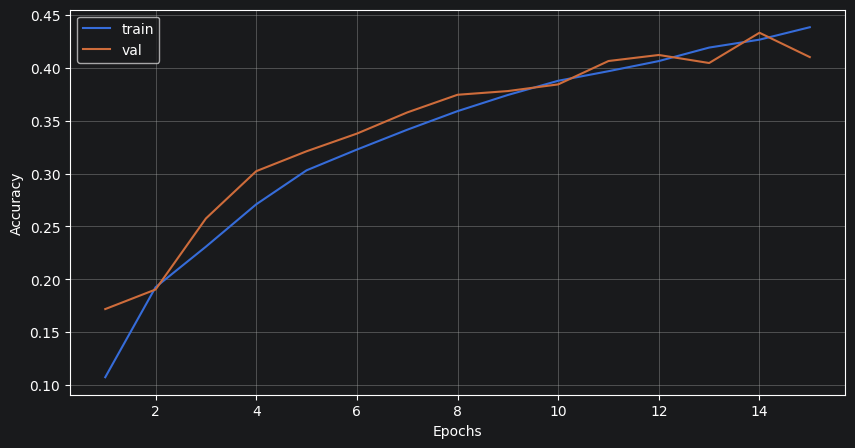

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, num_epochs + 1),
    history["train_accuracy"],
    label="train"
)

plt.plot(
    range(1, num_epochs + 1),
    history["val_accuracy"],
    label="val"
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

## Оценка модели на тестовой выборке

In [12]:
def test_loop(dataloader, model, criterion):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)

    test_loss = 0
    correct = 0

    model.eval()

    with torch.no_grad():
        for imgs, labels in dataloader:
            imgs = imgs.to(device)
            labels = labels.to(device)

            pred = model(imgs)
            loss = criterion(pred, labels)

            test_loss += loss.item()
            correct += (pred.argmax(dim=1) == labels).sum().item()

    test_loss /= num_batches
    test_accuracy = correct / size

    print(f"Test loss: {test_loss:>8f}")
    print(f"Test accuracy: {(100 * test_accuracy):>0.1f}%")

    return test_loss, test_accuracy

In [13]:
cifar_test_loss, cifar_test_accuracy = test_loop(
    cifar_test_loader,
    cifar_model,
    criterion,
)

Test loss: 1.647288
Test accuracy: 41.2%


## Вывод по cifar-10

Accuracy росла каждую эпоху, train loss постепенно уменьшалась => модель обучалась

Результаты train, validation и test примерно одинаковые, поэтому сильного переобучения нет

Тем не менее качество модели оставляет желать лучшего, но это "норма" для полносвязной млп на цифаре-10

# Классификация дорожных знаков GTSRB

В отличие от CIFAR-10, где используется 10 классов, в GTSRB надо классифицировать изображения по 43 классам

Так как изображения в GTSRB имеют разные размеры, приведем их к 32x32

In [14]:
gtsrb_transform = v2.Compose([
    v2.Resize((32, 32)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

In [15]:
gtsrb_full_train = datasets.GTSRB(
    root="data",
    split="train",
    download=True,
    transform=gtsrb_transform,
)

gtsrb_test = datasets.GTSRB(
    root="data",
    split="test",
    download=True,
    transform=gtsrb_transform,
)

100.0%
100.0%
100.0%


In [16]:
# разделяем train еще на train и validation 80/20
train_size = int(0.8 * len(gtsrb_full_train))
val_size = len(gtsrb_full_train) - train_size

gtsrb_train, gtsrb_val = random_split(
    gtsrb_full_train,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42),
)

In [17]:
print("Train:", len(gtsrb_train))
print("Val:", len(gtsrb_val))
print("Test:", len(gtsrb_test))

Train: 21312
Val: 5328
Test: 12630


dataloader

In [19]:
gtsrb_train_loader = DataLoader(
    gtsrb_train,
    batch_size=batch_size,
    shuffle=True,
)

gtsrb_val_loader = DataLoader(
    gtsrb_val,
    batch_size=batch_size,
    shuffle=False,
)

gtsrb_test_loader = DataLoader(
    gtsrb_test,
    batch_size=batch_size,
    shuffle=False,
)

## Модель для GTSRB

In [20]:
class GTSRBMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.layers_stack = nn.Sequential(
            nn.Linear(3 * 32 * 32, 1024),
            nn.ReLU(),

            nn.Linear(1024, 512),
            nn.ReLU(),

            nn.Linear(512, 256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, 43),
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.layers_stack(x)
        return logits

Создаем модель

In [21]:
gtsrb_model = GTSRBMLP().to(device)
print(gtsrb_model)

GTSRBMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers_stack): Sequential(
    (0): Linear(in_features=3072, out_features=1024, bias=True)
    (1): ReLU()
    (2): Linear(in_features=1024, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): ReLU()
    (6): Linear(in_features=256, out_features=128, bias=True)
    (7): ReLU()
    (8): Linear(in_features=128, out_features=43, bias=True)
  )
)


## Подсчет количества обучаемых параметров модели

In [22]:
def count_parameters(model):
    return sum(
        param.numel()
        for param in model.parameters()
        if param.requires_grad
    )


gtsrb_params = count_parameters(gtsrb_model)

print("Количество обучаемых параметров:", gtsrb_params)

Количество обучаемых параметров: 3841323


## Обучение GTSRB

Для обучения используем ту же функцию потерь `CrossEntropyLoss`, оптимизатор SGD и уже созданные функции `train_loop` и `val_loop`

In [23]:
num_epochs_gtsrb = 15
learning_rate_gtsrb = 1e-2

gtsrb_criterion = nn.CrossEntropyLoss()

gtsrb_optimizer = torch.optim.SGD(
    gtsrb_model.parameters(),
    lr=learning_rate_gtsrb,
)

In [24]:
gtsrb_history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
}

In [25]:
for epoch in range(num_epochs_gtsrb):
    print(f"Epoch {epoch + 1}")

    train_loss, train_accuracy = train_loop(
        gtsrb_train_loader,
        gtsrb_model,
        gtsrb_criterion,
        gtsrb_optimizer,
    )

    val_loss, val_accuracy = val_loop(
        gtsrb_val_loader,
        gtsrb_model,
        gtsrb_criterion,
    )

    gtsrb_history["train_loss"].append(train_loss)
    gtsrb_history["val_loss"].append(val_loss)
    gtsrb_history["train_accuracy"].append(train_accuracy)
    gtsrb_history["val_accuracy"].append(val_accuracy)

print("Done!")

Epoch 1
Train loss: 3.731333, train accuracy: 5.1%
Val loss: 3.695158, val accuracy: 5.3%

Epoch 2
Train loss: 3.610102, train accuracy: 5.7%
Val loss: 3.520442, val accuracy: 6.6%

Epoch 3
Train loss: 3.509388, train accuracy: 6.3%
Val loss: 3.495161, val accuracy: 8.9%

Epoch 4
Train loss: 3.491303, train accuracy: 7.2%
Val loss: 3.475660, val accuracy: 8.1%

Epoch 5
Train loss: 3.471179, train accuracy: 8.5%
Val loss: 3.449289, val accuracy: 10.6%

Epoch 6
Train loss: 3.432209, train accuracy: 10.7%
Val loss: 3.386341, val accuracy: 12.3%

Epoch 7
Train loss: 3.342641, train accuracy: 13.1%
Val loss: 3.257628, val accuracy: 15.2%

Epoch 8
Train loss: 3.176355, train accuracy: 15.8%
Val loss: 3.064346, val accuracy: 18.1%

Epoch 9
Train loss: 2.985369, train accuracy: 17.9%
Val loss: 2.912659, val accuracy: 18.6%

Epoch 10
Train loss: 2.849780, train accuracy: 19.6%
Val loss: 2.873329, val accuracy: 19.1%

Epoch 11
Train loss: 2.702975, train accuracy: 22.4%
Val loss: 3.049559, val a

## Визуализация функции потерь GTSRB

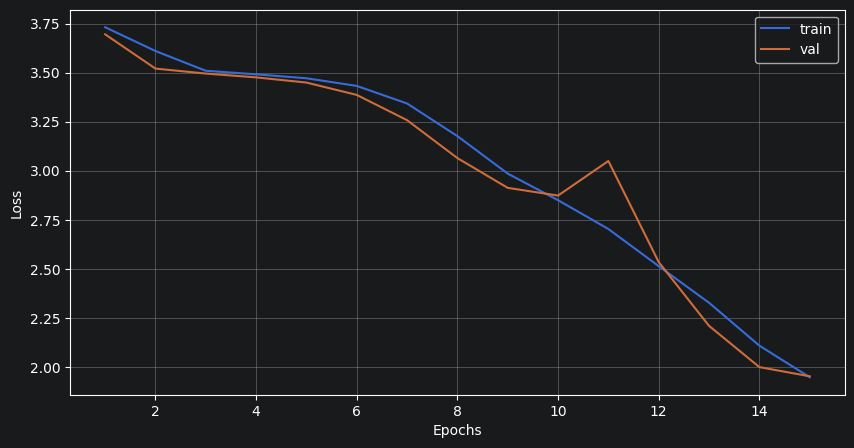

In [26]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, num_epochs_gtsrb + 1),
    gtsrb_history["train_loss"],
    label="train"
)

plt.plot(
    range(1, num_epochs_gtsrb + 1),
    gtsrb_history["val_loss"],
    label="val"
)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

## Визуализация accuracy GTSRB

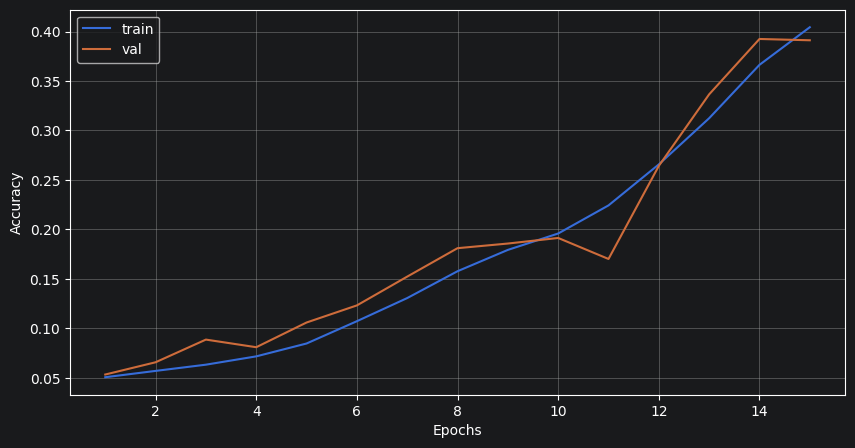

In [27]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, num_epochs_gtsrb + 1),
    gtsrb_history["train_accuracy"],
    label="train"
)

plt.plot(
    range(1, num_epochs_gtsrb + 1),
    gtsrb_history["val_accuracy"],
    label="val"
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

## Оценка GTSRB на тестовой выборке

In [28]:
gtsrb_test_loss, gtsrb_test_accuracy = test_loop(
    gtsrb_test_loader,
    gtsrb_model,
    gtsrb_criterion,
)

Test loss: 2.097940
Test accuracy: 36.1%


## Вывод по GTSRB

Accuracy выросла, train loss уменьшился => модель постепенно обучалась

На тестовой выборке модель показала accuracy 36.1% и test loss 2.0979

Результат на GTSRB оказался ниже, чем на CIFAR-10, тк в GTSRB используется больше классов (43 а не 10). Для полносвязной сети задача классификации такого набора данных оказалась сложнее